# ✍️ Handwritten Digit Recognition with Support Vector Machines (SVM)
**Margins, support vectors, the kernel trick, and tuning `C` and `gamma`**

**Objective:** Implement and understand Support Vector Machines: how they find the maximum-margin boundary, how kernels handle non-linear data, and how `C` and `gamma` control overfitting, then use them to read handwritten digits.
**Tools:** Scikit-learn, Pandas, Matplotlib (+ NumPy)
**Datasets:** small synthetic datasets (to *see* margins and kernels) and the **Digits dataset** (1,797 handwritten digit images, 8×8 pixels), built into scikit-learn, so **no download is needed**

**Pipeline**
1. Margins & support vectors: what the SVM optimises, and what `C` does
2. The kernel trick: linear vs polynomial vs RBF on non-linear data
3. Load & explore the Digits data
4. Does scaling help? (a surprising answer)
5. Tune `C` and `gamma` with a grid search (heatmap)
6. Compare kernels, evaluate the final model, inspect its mistakes
7. Support vectors, training cost and comparison with other classifiers

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_digits, make_moons, make_circles, make_blobs, make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
os.makedirs("images", exist_ok=True)   # plots are saved here
os.makedirs("data", exist_ok=True)
RANDOM_STATE = 42
print("✅ Libraries imported")

✅ Libraries imported


## 📐 Step 1: The Idea: Maximum Margin & Support Vectors
Many lines can separate two classes. An SVM picks the one with the **widest margin** (the "street" between the classes).
Only the points that touch the street edges, the **support vectors**, define the boundary; every other point could be removed without changing it.

**`C` controls the trade-off:** a **small C** allows a wide street with some points inside it or misclassified (soft margin, more regularisation);
a **large C** punishes every violation, giving a narrow street that fits the training data tightly (risk of overfitting).

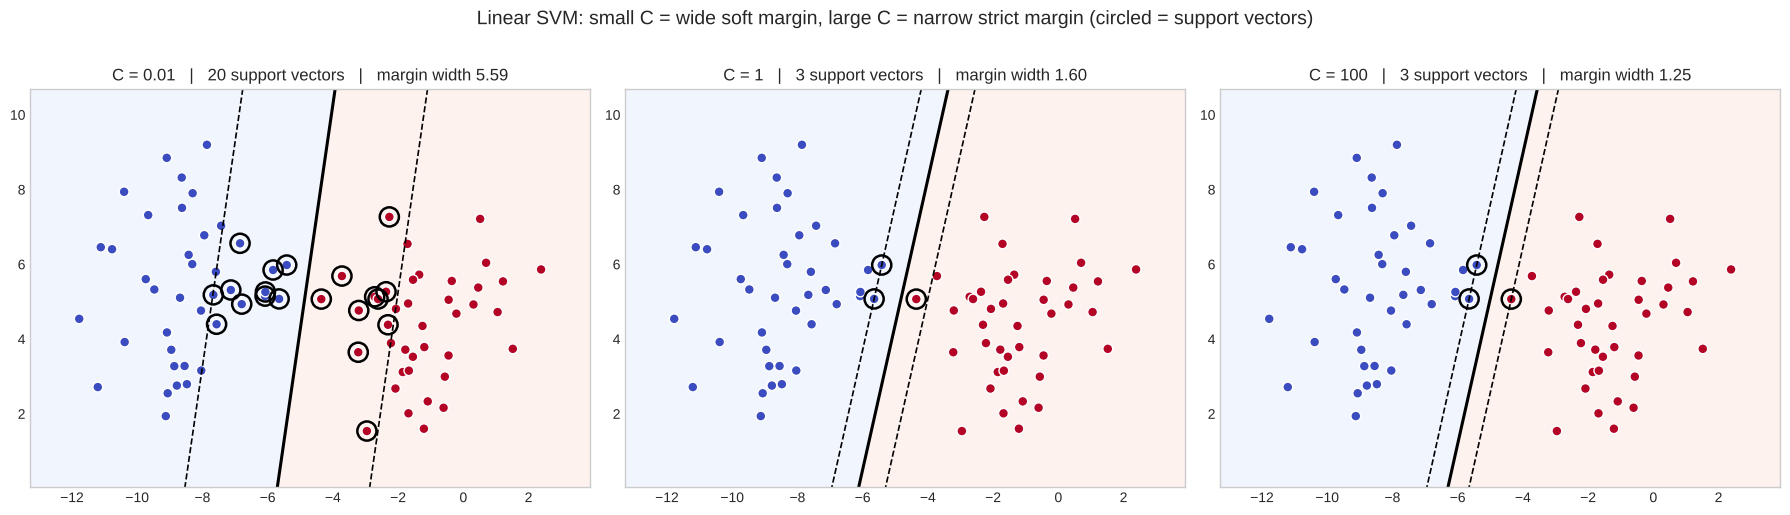

In [2]:
X_b, y_b = make_blobs(n_samples=80, centers=2, cluster_std=1.6, random_state=7)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
xx, yy = np.meshgrid(np.linspace(X_b[:, 0].min() - 1.5, X_b[:, 0].max() + 1.5, 300),
                     np.linspace(X_b[:, 1].min() - 1.5, X_b[:, 1].max() + 1.5, 300))
for ax, C_val in zip(axes, [0.01, 1, 100]):
    svm = SVC(kernel="linear", C=C_val).fit(X_b, y_b)
    zz = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0, alpha=0.12, cmap="coolwarm")
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.2, 2.2, 1.2])
    ax.scatter(X_b[:, 0], X_b[:, 1], c=y_b, cmap="coolwarm", edgecolor="white", s=50)
    ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1], s=190, facecolors="none", edgecolors="k", linewidths=1.8)
    width = 2 / np.linalg.norm(svm.coef_)
    ax.set_title(f"C = {C_val}   |   {svm.n_support_.sum()} support vectors   |   margin width {width:.2f}")
    ax.grid(False)
plt.suptitle("Linear SVM: small C = wide soft margin, large C = narrow strict margin (circled = support vectors)", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig("images/01_margin_and_C.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (margins)
- **C = 0.01:** a very wide margin (width ≈ 5.6) with **20 support vectors**: heavily regularised
- **C = 1:** margin width ≈ 1.6 with only **3 support vectors**
- **C = 100:** margin width ≈ 1.25, still 3 support vectors: the boundary is determined by just a few points, and a strict margin can be fragile if those points are noisy

## 🪄 Step 2: The Kernel Trick: Non-Linear Boundaries
A linear SVM fails when the classes are not separable by a straight line. The **kernel trick** lets the SVM act as if the data were mapped into a much higher-dimensional space
(where a flat boundary might work) **without ever computing that mapping**, using only kernel values K(x, x').
- **linear:** K = x·x'
- **polynomial:** K = (γ·x·x' + r)^d
- **RBF (Gaussian):** K = exp(−γ‖x − x'‖²): similarity decays with distance; `gamma` sets how local it is

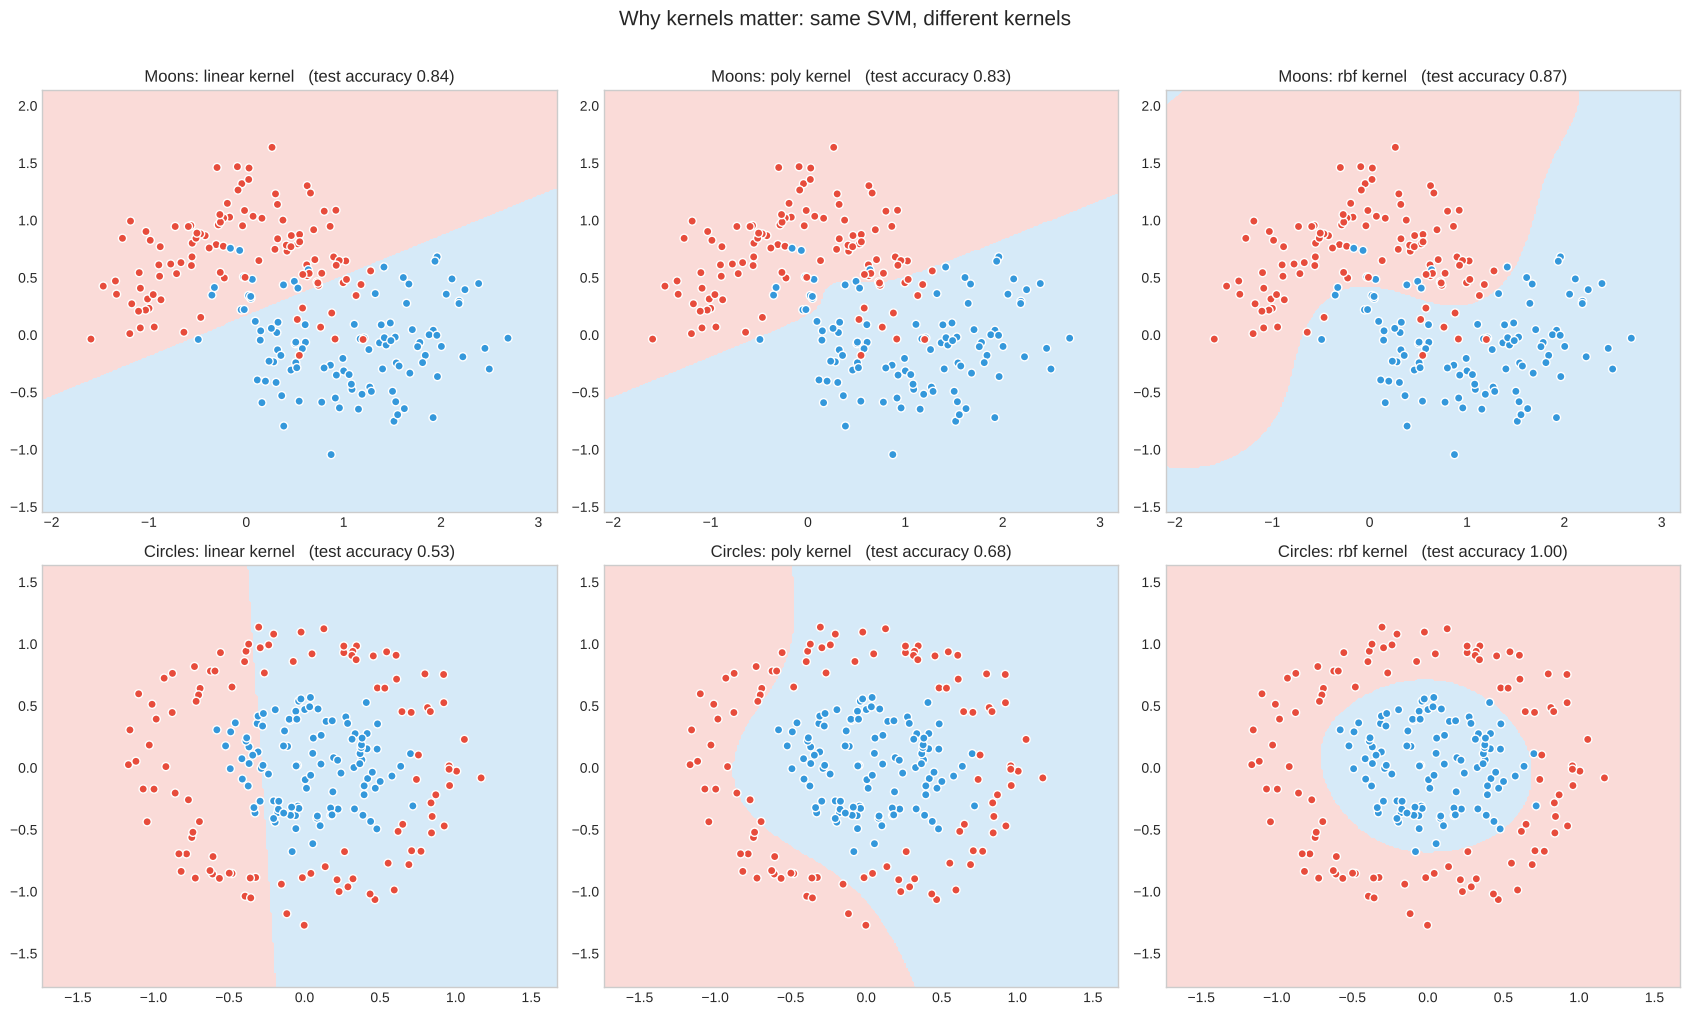

Moons / linear      0.844
Moons / poly        0.833
Moons / rbf         0.867
Circles / linear    0.533
Circles / poly      0.678
Circles / rbf       1.000
Name: test accuracy, dtype: float64

In [3]:
datasets = {
    "Moons": make_moons(n_samples=300, noise=0.25, random_state=RANDOM_STATE),
    "Circles": make_circles(n_samples=300, noise=0.12, factor=0.4, random_state=RANDOM_STATE),
}
kernels = ["linear", "poly", "rbf"]
bg = ListedColormap(["#fadbd8", "#d6eaf8"]); dots = ListedColormap(["#e74c3c", "#3498db"])

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
kernel_scores = {}
for row, (name, (Xs, ys)) in enumerate(datasets.items()):
    Xa, Xb_, ya, yb = train_test_split(Xs, ys, test_size=0.3, random_state=RANDOM_STATE, stratify=ys)
    gx, gy = np.meshgrid(np.linspace(Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5, 250),
                         np.linspace(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5, 250))
    for col, kernel in enumerate(kernels):
        m = make_pipeline(StandardScaler(), SVC(kernel=kernel)).fit(Xa, ya)
        grid_scaled = np.c_[gx.ravel(), gy.ravel()]
        zz = m.predict(grid_scaled).reshape(gx.shape)
        ax = axes[row, col]
        ax.contourf(gx, gy, zz, cmap=bg)
        ax.scatter(Xa[:, 0], Xa[:, 1], c=ya, cmap=dots, edgecolor="white", s=35)
        acc = m.score(Xb_, yb); kernel_scores[(name, kernel)] = acc
        ax.set_title(f"{name}: {kernel} kernel   (test accuracy {acc:.2f})")
        ax.grid(False)
plt.suptitle("Why kernels matter: same SVM, different kernels", y=1.01, fontsize=15)
plt.tight_layout()
plt.savefig("images/02_kernels_on_nonlinear_data.png", dpi=150, bbox_inches="tight")
plt.show()
pd.Series({f"{k[0]} / {k[1]}": round(v, 3) for k, v in kernel_scores.items()}, name="test accuracy")

### 📝 Observations (kernels)
- **Circles:** a linear SVM is at chance level (**0.53**), a polynomial kernel reaches 0.68, and the **RBF kernel is perfect (1.00)**: no straight line can separate a ring from its centre, but the RBF kernel can
- **Moons:** all kernels land at 0.83 to 0.87 because the classes overlap (noise), so the RBF kernel only edges ahead
- The kernel must match the shape of the data; **RBF is the usual default** because it can model very flexible boundaries

## 📥 Step 3: Load & Explore the Digits Dataset

In [4]:
digits = load_digits(as_frame=True)
X = digits.data
y = digits.target
pd.concat([X, y], axis=1).to_csv("data/digits.csv", index=False)

print("Shape:", X.shape, "(each row = one 8x8 image flattened to 64 pixel values)")
print("Missing values:", int(X.isnull().sum().sum()), "| Pixel range:", X.values.min(), "to", X.values.max())
print("Constant (always 0) pixels:", int((X.std() == 0).sum()))
print("\nImages per digit:", y.value_counts().sort_index().to_dict())

Shape: (1797, 64) (each row = one 8x8 image flattened to 64 pixel values)
Missing values: 0 | Pixel range: 0.0 to 16.0
Constant (always 0) pixels: 3

Images per digit: {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


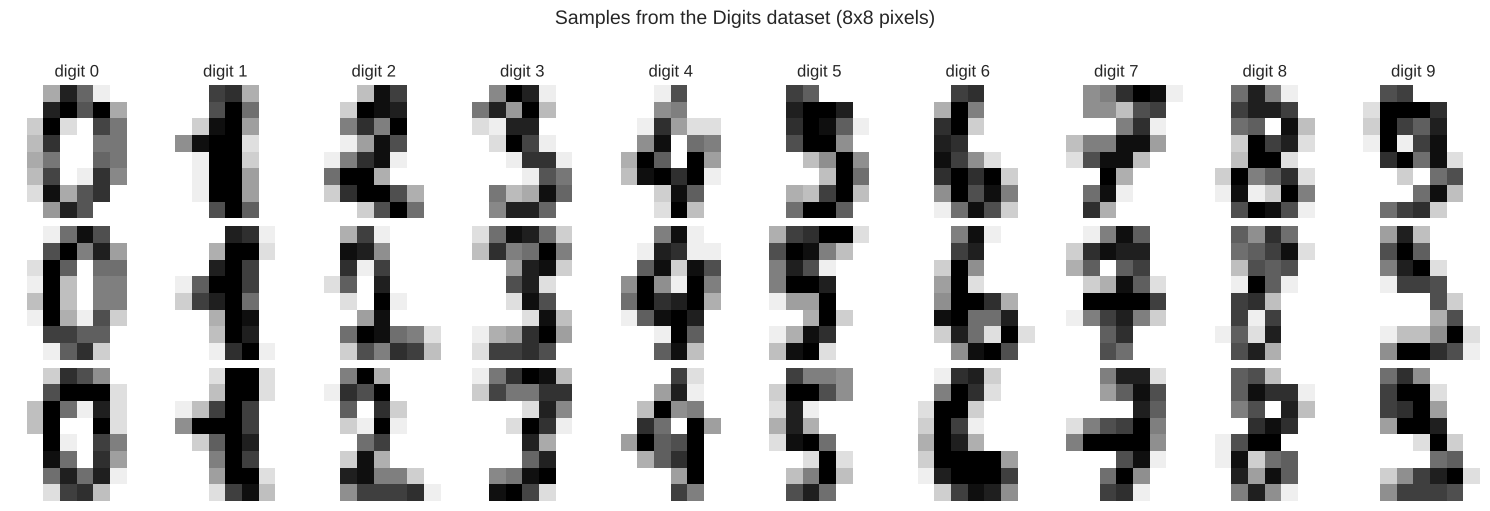

In [5]:
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for digit in range(10):
    idx = np.where(y == digit)[0][:3]
    for row, i in enumerate(idx):
        axes[row, digit].imshow(digits.images[i], cmap="gray_r")
        axes[row, digit].axis("off")
        if row == 0:
            axes[row, digit].set_title(f"digit {digit}")
plt.suptitle("Samples from the Digits dataset (8x8 pixels)", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig("images/03_digit_samples.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- **1,797 images, 64 pixel features** (8×8), values from **0 to 16**, no missing values
- **10 balanced classes** (174 to 183 images each), so plain accuracy is a fair metric
- 3 pixels are always 0 (corners), and the images are tiny and blurry: a good test of how well a model copes with noisy, high-dimensional data

## ✂️ Step 4: Split & Does Scaling Help?

Train: (1437, 64) | Test: (360, 64)


,CV accuracy,Test accuracy
Preprocessing,,
No scaling (raw pixels 0-16),0.9882,0.9917
MinMaxScaler (0-1),0.9882,0.9917
"StandardScaler (mean 0, std 1)",0.9812,0.9750


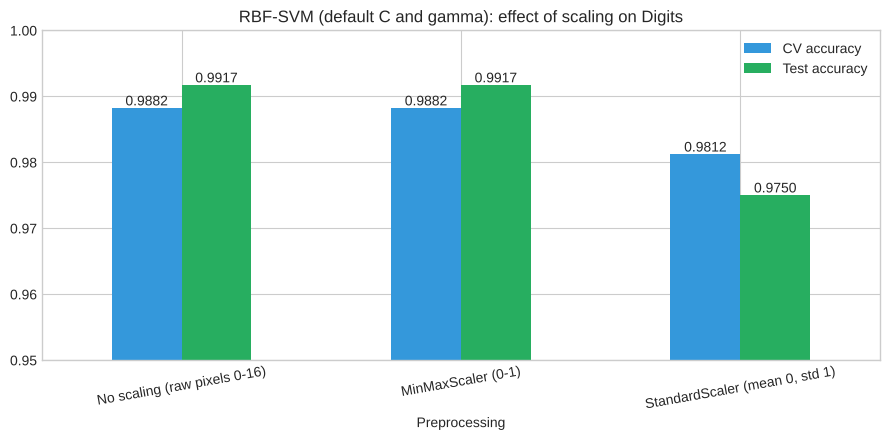

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

options = {
    "No scaling (raw pixels 0-16)": SVC(),
    "MinMaxScaler (0-1)": make_pipeline(MinMaxScaler(), SVC()),
    "StandardScaler (mean 0, std 1)": make_pipeline(StandardScaler(), SVC()),
}
rows = []
for name, model in options.items():
    rows.append({"Preprocessing": name, "CV accuracy": cross_val_score(model, X_train, y_train, cv=cv).mean(),
                 "Test accuracy": model.fit(X_train, y_train).score(X_test, y_test)})
scaling = pd.DataFrame(rows).set_index("Preprocessing").round(4)
display(scaling)

ax = scaling.plot(kind="bar", figsize=(9, 4.5), color=["#3498db", "#27ae60"], rot=10)
ax.set_ylim(0.95, 1.0); ax.set_title("RBF-SVM (default C and gamma): effect of scaling on Digits")
for c in ax.containers:
    ax.bar_label(c, fmt="%.4f")
plt.tight_layout()
plt.savefig("images/04_scaling_effect.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (scaling)
- **No scaling and MinMax scaling give the same result** (CV 0.9882, test 0.9917): all 64 features are already pixel intensities on the same 0 to 16 scale
- **`StandardScaler` is actually worse** (CV 0.9812, test 0.9750): it stretches nearly-constant border pixels (that are mostly noise) to unit variance, giving them as much influence as the informative centre pixels
- 💡 **Lesson:** SVMs are distance/kernel based and *usually* need scaling, but the right scaling depends on the data. When all features share one natural unit (pixels), keeping that structure is better than blindly standardizing. We use **MinMaxScaler** (inside a Pipeline, so it is fitted on training data only)

## 🔧 Step 5: Tune `C` and `gamma` (RBF kernel)
- **C**: how strictly training errors are punished (small = smoother boundary, large = tight fit)
- **gamma**: how far one training point's influence reaches (small = broad, smooth boundary; large = each point only influences its immediate surroundings → overfits)

They interact, so we search them **together** with 5-fold cross-validation on the training data.

Best parameters: {'C': 1, 'gamma': 0.1}
Best CV accuracy: 0.9882


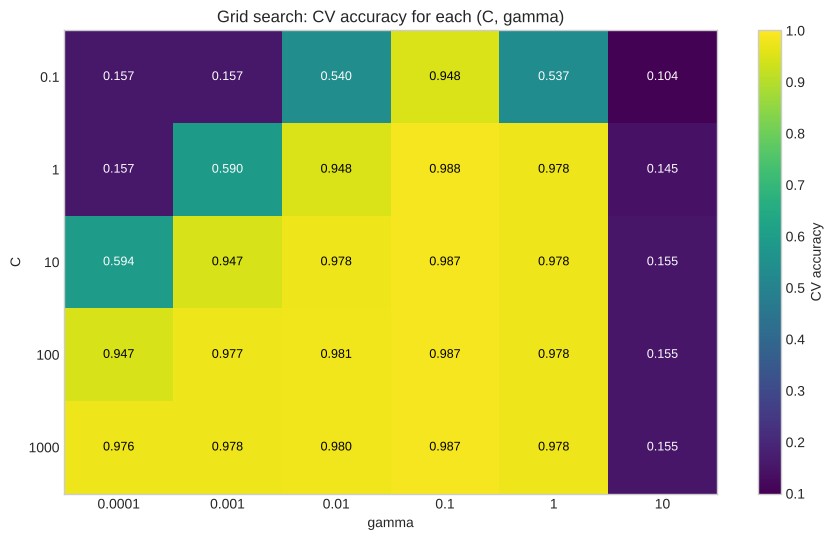

In [7]:
C_grid = [0.1, 1, 10, 100, 1000]
gamma_grid = [0.0001, 0.001, 0.01, 0.1, 1, 10]

grid = GridSearchCV(make_pipeline(MinMaxScaler(), SVC()), {"svc__C": C_grid, "svc__gamma": gamma_grid}, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
print(f"Best CV accuracy: {grid.best_score_:.4f}")

scores = pd.DataFrame(grid.cv_results_).pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")

plt.figure(figsize=(9, 5.5))
plt.imshow(scores.values.astype(float), cmap="viridis", aspect="auto", vmin=0.1, vmax=1.0)
plt.colorbar(label="CV accuracy")
plt.xticks(range(len(gamma_grid)), gamma_grid); plt.yticks(range(len(C_grid)), C_grid)
for i in range(len(C_grid)):
    for j in range(len(gamma_grid)):
        v = float(scores.values[i, j])
        plt.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v < 0.7 else "black", fontsize=9)
plt.xlabel("gamma"); plt.ylabel("C"); plt.title("Grid search: CV accuracy for each (C, gamma)")
plt.grid(False)
plt.tight_layout()
plt.savefig("images/05_grid_search_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (C × gamma)
- Best: **C = 1, gamma = 0.1**, CV accuracy **0.9882**
- A **ridge of good values** runs diagonally: small gamma needs large C and vice versa, and C ≥ 10 with gamma = 0.1 stays at **0.987**
- **gamma = 10** collapses to ≈ 0.15 (random guessing) for every C: each training point only "sees" itself, so the model memorises. **gamma ≤ 0.001 with small C** also fails (≈ 0.16): the boundary is too smooth to separate 10 classes (underfitting)
- Once C is large enough (≥ 10), increasing it further changes nothing: the margin is already strict

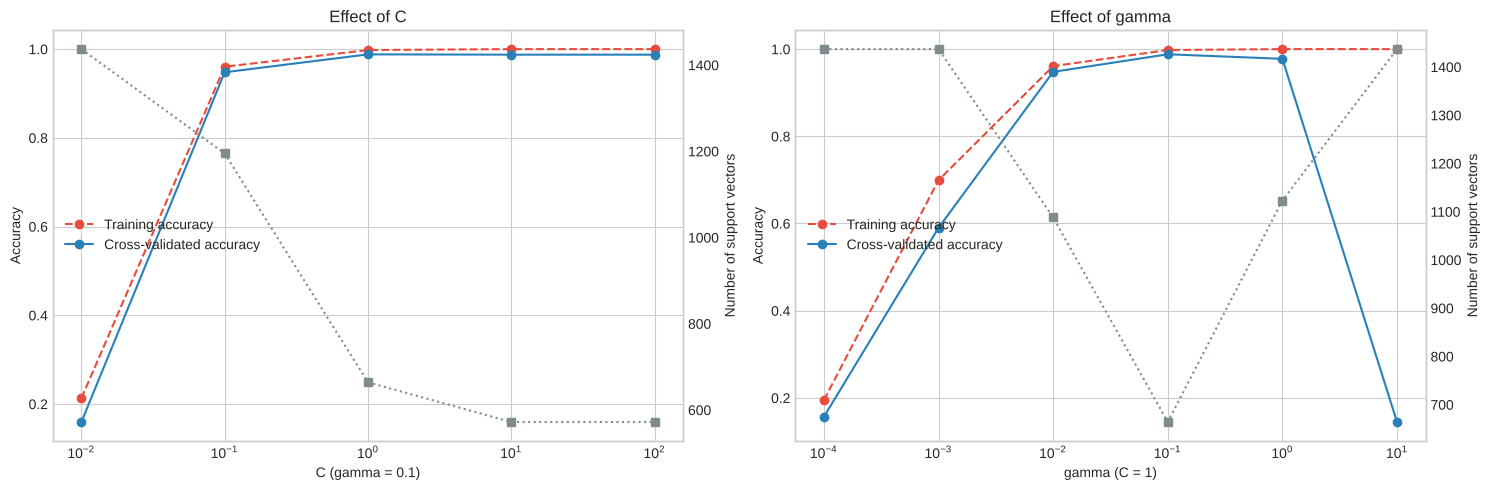

,Train,CV,Support vectors
C,,,
0.01,0.213,0.159,1437
0.10,0.960,0.948,1195
1.00,0.998,0.988,664
10.00,1.000,0.987,572
100.00,1.000,0.987,572


,Train,CV,Support vectors
gamma,,,
0.0001,0.195,0.157,1437
0.0010,0.699,0.590,1437
0.0100,0.961,0.948,1088
0.1000,0.998,0.988,664
1.0000,1.000,0.978,1123
10.0000,1.000,0.145,1437


In [8]:
# How do C and gamma change training vs validation accuracy and the number of support vectors?
rows_c, rows_g = [], []
for C_val in [0.01, 0.1, 1, 10, 100]:
    m = make_pipeline(MinMaxScaler(), SVC(C=C_val, gamma=0.1)).fit(X_train, y_train)
    rows_c.append({"C": C_val, "Train": m.score(X_train, y_train), "CV": cross_val_score(make_pipeline(MinMaxScaler(), SVC(C=C_val, gamma=0.1)), X_train, y_train, cv=cv).mean(),
                   "Support vectors": int(m.named_steps["svc"].n_support_.sum())})
for g in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
    m = make_pipeline(MinMaxScaler(), SVC(C=1, gamma=g)).fit(X_train, y_train)
    rows_g.append({"gamma": g, "Train": m.score(X_train, y_train), "CV": cross_val_score(make_pipeline(MinMaxScaler(), SVC(C=1, gamma=g)), X_train, y_train, cv=cv).mean(),
                   "Support vectors": int(m.named_steps["svc"].n_support_.sum())})
c_df, g_df = pd.DataFrame(rows_c).set_index("C"), pd.DataFrame(rows_g).set_index("gamma")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, df_, xlabel, title in [(axes[0], c_df, "C (gamma = 0.1)", "Effect of C"), (axes[1], g_df, "gamma (C = 1)", "Effect of gamma")]:
    ax.semilogx(df_.index, df_["Train"], "o--", color="#e74c3c", label="Training accuracy")
    ax.semilogx(df_.index, df_["CV"], "o-", color="#2980b9", label="Cross-validated accuracy")
    ax.set_xlabel(xlabel); ax.set_ylabel("Accuracy"); ax.set_title(title); ax.legend(loc="center left")
    ax2 = ax.twinx(); ax2.semilogx(df_.index, df_["Support vectors"], "s:", color="#7f8c8d", label="Support vectors")
    ax2.set_ylabel("Number of support vectors"); ax2.grid(False)
plt.tight_layout()
plt.savefig("images/06_effect_of_C_and_gamma.png", dpi=150, bbox_inches="tight")
plt.show()

display(c_df.round(3)); display(g_df.round(3))

### 📝 Observations (C and gamma separately)
- **C:** C = 0.01 underfits completely (accuracy ≈ 0.2, **all 1,437 training points are support vectors**). From C = 1 the model is accurate; going to C = 10 or 100 raises train accuracy to 1.000 but **CV stays ≈ 0.987**
- **gamma:** gamma = 10 gives train accuracy **1.000** but CV **0.145**: the textbook overfit. The sweet spot is gamma ≈ 0.1 (train 0.998, CV 0.988)
- The **number of support vectors** is high when the model is under- or over-fitted (1,437 at both extremes) and lowest (**664**, 46% of the data) at the good setting: a model that needs fewer support vectors is simpler and faster at prediction time

## 🔀 Step 6: Which Kernel? (each tuned over C)

,Best C,CV accuracy,Test accuracy
Kernel,,,
linear,1,0.9784,0.9861
poly,1,0.9916,0.9861
rbf,10,0.9882,0.9944
sigmoid,1,0.9137,0.8917


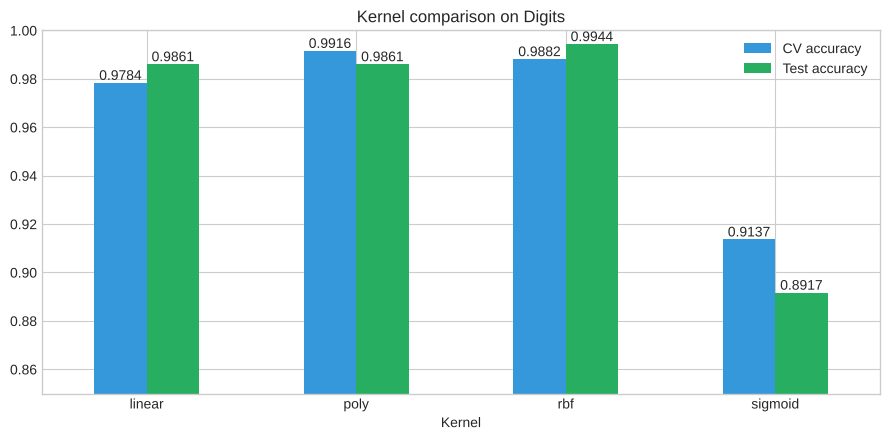

In [9]:
rows = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    gk = GridSearchCV(make_pipeline(MinMaxScaler(), SVC(kernel=kernel)), {"svc__C": [0.1, 1, 10, 100]}, cv=cv, n_jobs=-1).fit(X_train, y_train)
    rows.append({"Kernel": kernel, "Best C": gk.best_params_["svc__C"], "CV accuracy": gk.best_score_, "Test accuracy": gk.score(X_test, y_test)})
kernel_df = pd.DataFrame(rows).set_index("Kernel").round(4)
display(kernel_df)

ax = kernel_df[["CV accuracy", "Test accuracy"]].plot(kind="bar", figsize=(9, 4.5), color=["#3498db", "#27ae60"], rot=0)
ax.set_ylim(0.85, 1.0); ax.set_title("Kernel comparison on Digits")
for c in ax.containers:
    ax.bar_label(c, fmt="%.4f")
plt.tight_layout()
plt.savefig("images/07_kernel_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (kernels on digits)
| Kernel | CV accuracy | Test accuracy |
|---|---|---|
| linear | 0.9784 | 0.9861 |
| polynomial | **0.9916** | 0.9861 |
| **RBF** | 0.9882 | **0.9944** |
| sigmoid | 0.9137 | 0.8917 |

Linear, polynomial and RBF kernels are all excellent (≥ 0.978 CV): digits are close to linearly separable in 64 dimensions. The **sigmoid kernel is clearly worst**.
The differences between the top three are about 1 point (a few images on a 360-image test set), so **don't over-interpret the ranking**. RBF is kept as the main model.

## 🎯 Step 7: Evaluate the Final Model on the Test Set

Test accuracy: 0.9917  (357 of 360 correct)

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.947     1.000     0.973        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     1.000     1.000        36
           7      0.973     1.000     0.986        36
           8      1.000     0.943     0.971        35
           9      1.000     0.972     0.986        36

    accuracy                          0.992       360
   macro avg      0.992     0.992     0.992       360
weighted avg      0.992     0.992     0.992       360



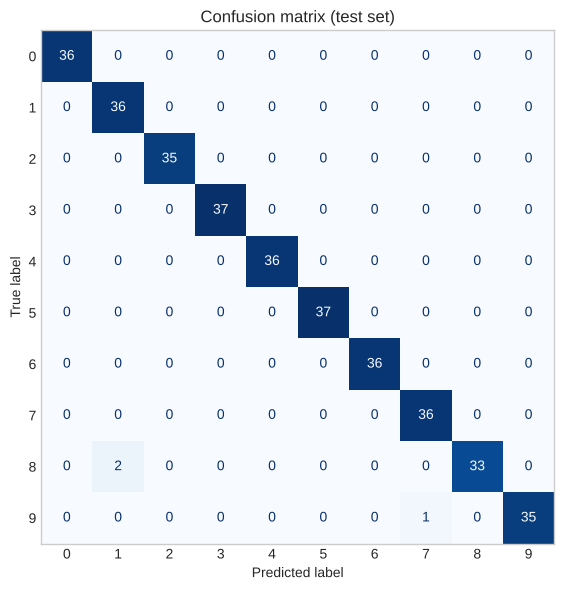

In [10]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}  ({int((y_pred == y_test).sum())} of {len(y_test)} correct)\n")
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion matrix (test set)"); ax.grid(False)
plt.tight_layout()
plt.savefig("images/08_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Misclassified test images: 3


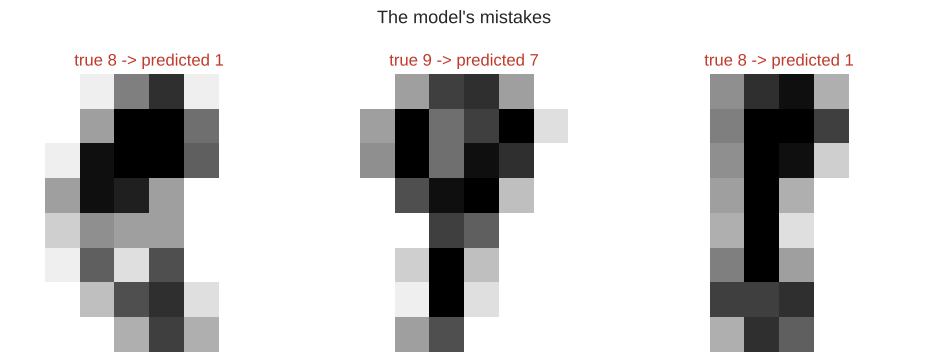

In [11]:
wrong = np.where(y_pred != y_test.values)[0]
print("Misclassified test images:", len(wrong))

fig, axes = plt.subplots(1, max(len(wrong), 2), figsize=(3.2 * max(len(wrong), 2), 3.4))
for ax, i in zip(np.atleast_1d(axes), wrong):
    img = digits.images[X_test.index[i]]
    ax.imshow(img, cmap="gray_r"); ax.axis("off")
    ax.set_title(f"true {y_test.iloc[i]} -> predicted {y_pred[i]}", color="#c0392b")
plt.suptitle("The model's mistakes", y=1.05, fontsize=13)
plt.tight_layout()
plt.savefig("images/09_misclassified_digits.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (test performance)
- **Test accuracy 0.9917** (357 of 360), macro F1 0.992. Digits 0, 2, 3, 4, 5 and 6 are classified perfectly
- Only **3 mistakes**: two **8s read as 1** and one **9 read as 7**. These are blurry 8×8 images where a thin 8 or a 9 with a short loop really does look like a 1 or a 7
- The final model uses **664 support vectors** (of 1,437 training images): the boundary is defined by the hard, ambiguous examples near the class borders
- ⚠️ With 360 test images, one mistake is 0.28 points, so treat 0.99 as "≈ 0.99, plus or minus a little"; the CV score (0.988) is the steadier number

## ⚖️ Step 8: Comparison with Other Classifiers & the Cost of SVMs

,CV accuracy,Test accuracy
Model,,
Logistic Regression,0.9638,0.9583
KNN (k=5),0.9868,0.9833
Random Forest (300),0.9749,0.9694
"SVM (RBF, tuned)",0.9882,0.9917


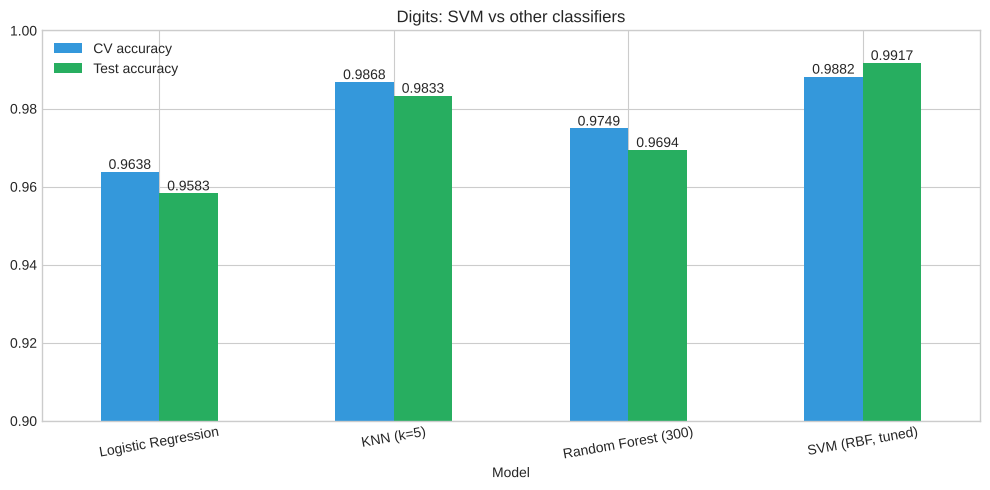

In [12]:
candidates = {
    "Logistic Regression": make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=3000)),
    "KNN (k=5)": make_pipeline(MinMaxScaler(), KNeighborsClassifier(5)),
    "Random Forest (300)": RandomForestClassifier(300, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM (RBF, tuned)": best_model,
}
rows = []
for name, m in candidates.items():
    rows.append({"Model": name, "CV accuracy": cross_val_score(m, X_train, y_train, cv=cv).mean(),
                 "Test accuracy": m.fit(X_train, y_train).score(X_test, y_test)})
comparison = pd.DataFrame(rows).set_index("Model").round(4)
display(comparison)

ax = comparison.plot(kind="bar", figsize=(10, 5), color=["#3498db", "#27ae60"], rot=10)
ax.set_ylim(0.9, 1.0); ax.set_title("Digits: SVM vs other classifiers")
for c in ax.containers:
    ax.bar_label(c, fmt="%.4f")
plt.tight_layout()
plt.savefig("images/10_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

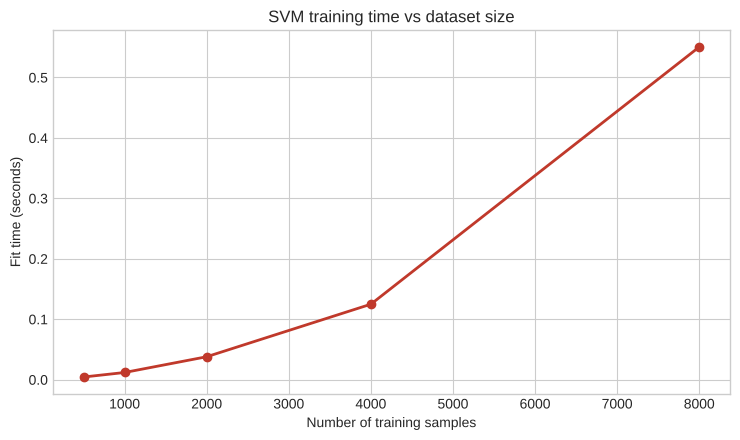

{500: 0.0, 1000: 0.01, 2000: 0.04, 4000: 0.12, 8000: 0.55}
Empirical scaling: fit time grows like n^1.8  (a straight line would be n^1.0)


In [13]:
# Training time grows quickly with the number of samples (roughly between O(n^2) and O(n^3))
sizes = [500, 1000, 2000, 4000, 8000]
times = []
for n in sizes:
    Xs, ys = make_classification(n_samples=n, n_features=20, n_informative=10, random_state=RANDOM_STATE)
    t0 = time.time(); SVC(kernel="rbf").fit(Xs, ys); times.append(time.time() - t0)

plt.figure(figsize=(7.5, 4.5))
plt.plot(sizes, times, "o-", color="#c0392b", linewidth=2)
plt.xlabel("Number of training samples"); plt.ylabel("Fit time (seconds)")
plt.title("SVM training time vs dataset size")
plt.tight_layout()
plt.savefig("images/11_training_time.png", dpi=150, bbox_inches="tight")
plt.show()
print({n: round(t, 2) for n, t in zip(sizes, times)})
slope = np.polyfit(np.log(sizes[1:]), np.log(np.maximum(times[1:], 1e-4)), 1)[0]
print(f"Empirical scaling: fit time grows like n^{slope:.1f}  (a straight line would be n^1.0)")

### 📝 Observations (comparison & cost)
| Model | CV accuracy | Test accuracy |
|---|---|---|
| Logistic Regression | 0.9638 | 0.9583 |
| KNN (k = 5) | 0.9868 | 0.9833 |
| Random Forest (300) | 0.9749 | 0.9694 |
| **SVM (RBF, tuned)** | **0.9882** | **0.9917** |

- The SVM is the best of the four, but **KNN is within 0.15 points on CV**, which is well inside the noise of a 360-image test set. All four models exceed 0.95
- Logistic regression is the weakest here: a single linear boundary per class is less flexible than the RBF kernel
- Unlike on the breast cancer data, a simple linear model does **not** win: handwritten digits have curved class boundaries, which is exactly where kernels help

**Cost:** SVM training time grows much faster than linearly with the number of samples: the printed exponent is **roughly 2** (time ∝ n²), so doubling the data about quadruples the fit time (exact numbers depend on the machine).
That is why SVMs are a great choice for **small and medium datasets** (up to tens of thousands of rows) but impractical for millions of rows, where linear models or tree ensembles scale better.

## ✅ Conclusion
- An SVM finds the **maximum-margin** boundary, and only the **support vectors** define it. `C` trades margin width against training errors
- The **kernel trick** gives non-linear boundaries: on the circles data a linear SVM scored 0.53 and the RBF kernel 1.00
- `C` and `gamma` must be tuned **together** (heatmap): gamma too large memorises (train 1.00, CV 0.15), too small underfits. The best setting (C = 1, gamma = 0.1) reaches **CV 0.988 and test 0.992** (3 errors in 360 digits)
- Scaling is not automatic: on pixel data, **MinMax / no scaling beat StandardScaler** (0.988 vs 0.981 CV)
- SVMs excel on small, high-dimensional, clean problems like this one, but training cost grows quickly with data size, and they give no direct probabilities or feature importances

## 🎤 Interview Questions: Short Answers
1. **What is an SVM and what is the margin?** A classifier that finds the hyperplane separating classes with the **maximum margin** (the widest gap between the classes). A larger margin generally means better generalisation.
2. **What are support vectors?** The training points that lie on or inside the margin. They alone define the boundary: removing any other point changes nothing. Fewer support vectors means a simpler model (here 664 of 1,437).
3. **Hard margin vs soft margin, and what does C do?** A hard margin allows no violations (only works for perfectly separable data). A soft margin allows some, with penalty C: **small C** = wide margin, more tolerance (underfit risk); **large C** = narrow margin, few violations (overfit risk).
4. **What is the kernel trick?** Computing inner products in a high-dimensional feature space through a kernel function K(x, x') without ever building that space, so non-linear boundaries become cheap. Common kernels: linear, polynomial, RBF, sigmoid.
5. **What does gamma do in the RBF kernel?** It sets how far a single point's influence reaches. **Small gamma** = smooth, broad boundary (underfit); **large gamma** = each point only affects its neighbourhood, with a wiggly boundary (overfit: train 1.00, CV 0.15 at gamma = 10).
6. **Why is scaling important for SVM, and when is it not?** Kernels use distances, so large-range features dominate; scaling usually helps. But when all features share one natural scale (pixels), standardizing can amplify noise: on Digits MinMax beat StandardScaler.
7. **How do you choose the kernel?** Start with RBF (flexible default) and linear (fast, strong when features are many or the data is almost linearly separable); compare with cross-validation, and tune `C` (and `gamma`) together with a grid or random search.
8. **SVM vs logistic regression?** Logistic regression optimises log-loss and gives calibrated probabilities; SVM maximises the margin (hinge loss) and, with kernels, models non-linear boundaries. SVMs often win on small, high-dimensional data, while logistic regression is faster and easier to interpret.
9. **How does an SVM handle multiple classes?** It is binary by design; scikit-learn's `SVC` trains one-vs-one classifiers (45 of them for 10 digits) and votes, while `LinearSVC` uses one-vs-rest.
10. **How do you get probabilities from an SVM?** `SVC(probability=True)` fits a Platt-scaling calibration with extra cross-validation (slower); otherwise use `decision_function` scores (signed distance to the boundary).
11. **What are the drawbacks of SVMs?** Training time grows roughly between O(n²) and O(n³), memory is heavy for large datasets, results are sensitive to `C`, `gamma` and scaling, and there are no built-in probabilities or feature importances. Use `class_weight='balanced'` for imbalanced data.
12. **Can SVMs do regression?** Yes: Support Vector Regression (`SVR`) fits a tube of width epsilon around the data and ignores errors inside it.